In [1]:
"""
%pip install pandas
%pip install numpy
%pip install matplotlib
%pip install PIL
%pip install pathlib
%pip install scikit-learn
%pip install torch
%pip install torch torchvision
%pip install openpyxl
%pip install lime
%pip install scikit-image
"""

'\n%pip install pandas\n%pip install numpy\n%pip install matplotlib\n%pip install PIL\n%pip install pathlib\n%pip install scikit-learn\n%pip install torch\n%pip install torch torchvision\n%pip install openpyxl\n%pip install lime\n%pip install scikit-image\n'

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report

import torch
from torchvision.transforms import v2
from torch.utils.data import Dataset, DataLoader

from scipy import ndimage as ndi
from lime import lime_image
from skimage.segmentation import slic, mark_boundaries

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

c:\Users\Jaxon\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Loading in the data

In [3]:
ROOT = Path(".")
IMG_DIR = ROOT / "Image"

FOLDERS = ["Normal", "Stage 1 ROP", "Stage 2 ROP", "Stage 3 ROP", "Stage 4 ROP", "Stage 5 ROP"]

# one row per image file, stacked across class folders
files = pd.concat(
    [pd.DataFrame({"image": [p.name for p in sorted((IMG_DIR / f).iterdir())
                             if p.suffix.lower() in {".jpg", ".jpeg"}],
                   "label": f})
     for f in FOLDERS],
    ignore_index=True,
)
files["path"] = [str(IMG_DIR / lab / name) for lab, name in zip(files["label"], files["image"])]

# attach patient metadata by filename
info = pd.read_excel(ROOT / "img_info.xlsx")
imgs = files.merge(info, on="image", how="left", validate="one_to_one").rename(columns={"image": "file"})
assert imgs["patient_id"].notna().all(), "some images are missing from img_info.xlsx"

SEVERITY = {"Stage 1 ROP": "Mild ROP", "Stage 2 ROP": "Mild ROP", "Stage 3 ROP": "Moderate ROP",
            "Stage 4 ROP": "Severe ROP", "Stage 5 ROP": "Severe ROP"}
imgs["severity"] = imgs["label"].map(SEVERITY)           
imgs["ROP"] = (imgs["label"] != "Normal").astype(int)    

print("imgs:", imgs.shape[0])
print("features:", imgs.columns)

imgs: 1527
features: Index(['file', 'label', 'path', 'patient_id', 'gender', 'gestational_age',
       'birth_weight', 'plurality', 'delivery_mode', 'categories', 'severity',
       'ROP'],
      dtype='str')


# Loading in the images

In [ ]:
# Image dimensions when loaded in
size = 512

def load(p, size):
    with Image.open(p) as im:
        return np.asarray(im.convert("RGB").resize(size))

# Opening the jpeg images as numpy arrays with the standardized size
imgs["image"] = imgs["path"].apply(lambda p: load(p, (size,size)))   

# Better to seperate the memory heavy image data from the rest of the data
X_all = np.stack(imgs["image"].values)
imgs = imgs.drop(columns="image")

# 5-fold cross-validation

In [5]:
# Similar to the regular KFold() function but able to handle stratification
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
# Initilizing as -1 makes overlooking skipped rows harder to overlook
imgs["fold"] = -1
# y = label to stratify on, every group stays in the same fold (so patients stay in the same fold)
for k, (train_idx, val_idx) in enumerate(sgkf.split(X=imgs, y=imgs["label"], groups=imgs["patient_id"])):
    # assigning images to a fold
    imgs.loc[val_idx, "fold"] = k

print("every image is in a fold:", (imgs["fold"] >= 0).all())
print("No patient is split between folds:", imgs.groupby("patient_id")["fold"].nunique().max() == 1)

every image is in a fold: True
No patient is split between folds: True


# Data pre-processing and augmentation transformers

In [6]:
# Compose() chains a list of transforms into a single callable that applies them in order
# where v2 is what is being transformed
train_tf = v2.Compose([
    v2.ToImage(),                                    # HWC uint8 array -> CHW tensor
    v2.ToDtype(torch.float32, scale=True),           # intensity normalization: [0, 255] -> [0, 1]
    v2.RandomHorizontalFlip(p=0.5),                  # random horizontal flip
    v2.RandomAffine(degrees=5, scale=(0.9, 1.1),     # rotation in [-5, 5] deg and scale in [0.9, 1.1], one resampling step
                    interpolation=v2.InterpolationMode.BILINEAR, fill=0),
    v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.0),
])

val_tf = v2.Compose([                                # validation: normalization only
    v2.ToImage(),                                    # no augmentation
    v2.ToDtype(torch.float32, scale=True),
])

# Assigning a dataset for each task

In [7]:
# Class names for later reports
OCC_CLASSES = ["Normal", "ROP"]                                  
SEV_MAP = {"Mild ROP": 0, "Moderate ROP": 1, "Severe ROP": 2}
SEV_CLASSES = list(SEV_MAP)

# ROP occurence task
occ_df = imgs.assign(y=imgs["ROP"])
# severity task
sev_df = imgs[imgs["severity"].notna()].assign(
    # encoding
    y=lambda d: d["severity"].map({"Mild ROP": 0, "Moderate ROP": 1, "Severe ROP": 2}))

print("-------[Occurence Task]-------")
print("occurence task unique patients:", occ_df["patient_id"].unique().shape[0])
print("occurence task images:", occ_df.shape[0])
print("num classes:", occ_df["ROP"].unique().shape[0])
print(pd.crosstab(imgs["ROP"], imgs["fold"]))
print("\n")
print("-------[Severity Task]-------")
print("severity task unique patients:", sev_df["patient_id"].unique().shape[0])
print("severity task images:", sev_df.shape[0])
print("num classes:", sev_df["severity"].unique().shape[0])
print(pd.crosstab(imgs["severity"], imgs["fold"]))

-------[Occurence Task]-------
occurence task unique patients: 916
occurence task images: 1527
num classes: 2
fold    0    1    2    3    4
ROP                          
0     124  125  124  125  125
1     182  181  181  180  180


-------[Severity Task]-------
severity task unique patients: 550
severity task images: 904
num classes: 3
fold            0    1    2    3    4
severity                             
Mild ROP      116  114  115  114  115
Moderate ROP   48   49   48   48   48
Severe ROP     18   18   18   18   17


# Image Loader

In [8]:
class ROPDataset(Dataset):
    """Hands the DataLoader one (image, label) pair at a time, applying the transform on the fly."""

    def __init__(self, X, idx, y, tf):
        # X   : the full image array (1527, 512, 512, 3), uint8. Stored by reference, not copied.
        # idx : row numbers in X that belong to this dataset (e.g. this fold's training rows)
        # y   : labels for those same rows, in the same order as idx
        # tf  : transform pipeline (train_tf or val_tf)
        # np.asarray turns the pandas Index / Series into plain numpy arrays
        self.X, self.idx, self.y, self.tf = X, np.asarray(idx), np.asarray(y), tf

    def __len__(self):
        # the DataLoader calls this to know how many samples there are (which sets batches per epoch)
        return len(self.idx)

    def __getitem__(self, i):
        # i is a position within this dataset (0 .. len-1), not a row number in X.
        # self.idx[i] translates it to the row in X, and self.X[...] is one (512, 512, 3) uint8 image.
        # self.tf(...) returns a float tensor (3, 512, 512). The random steps in train_tf are
        # re-drawn on every call, so the same image looks different each epoch (X itself isn't modified).
        # int(self.y[i]) is a plain Python int label; the DataLoader stacks these into a tensor.
        return self.tf(self.X[self.idx[i]]), int(self.y[i])


def make_loaders(df, k, bs=16):
    # df: occ_df or sev_df (needs "fold" and "y" columns). k: the fold held out for validation.
    tr, va = df[df["fold"] != k], df[df["fold"] == k]    # four folds to train on, one to validate on

    # tr.index holds the original row numbers in imgs / X_all (they survive the filtering),
    # and tr["y"] holds their labels in the same order
    train_dl = DataLoader(ROPDataset(X_all, tr.index, tr["y"], train_tf), batch_size=bs, shuffle=True)  # new order each epoch
    val_dl   = DataLoader(ROPDataset(X_all, va.index, va["y"], val_tf),   batch_size=bs)               # no shuffle: order stays fixed
    # DataLoader() provides effecient data handling during training and evaluation
    return train_dl, val_dl

# Testing augmentation

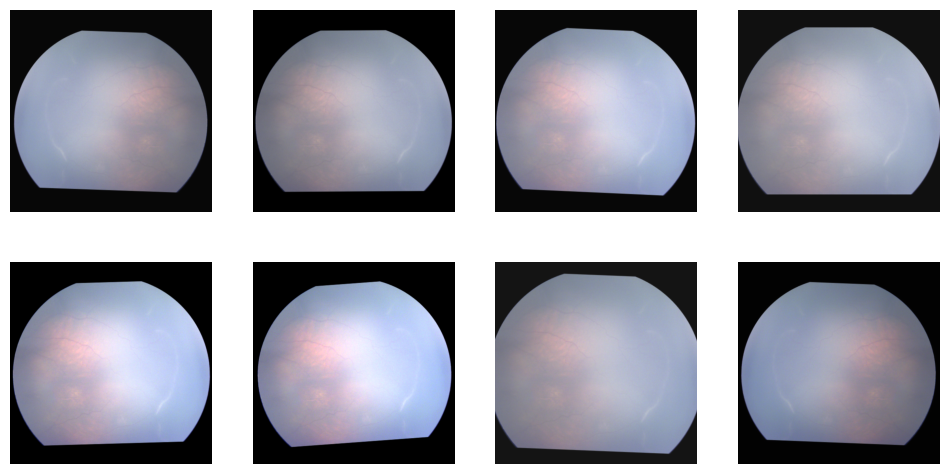

In [9]:
# X_all is all the images only
img = X_all[sev_df.index[0]] # gets an index for the image data
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
# Do 8 times for the same image
for ax in axes.flat:
    ax.imshow(train_tf(img).permute(1, 2, 0).clamp(0, 1).numpy())
    # train_tf applies the transforms to a given image (roation, color jitter, etc)
    # permute() changes the tensors shape from (channels, height, width) to (hight, width, channels)
    # clamp(0,1) ensures the pixels are within a valid range for images
    # numpy() converts the tensor to a numpy array
    ax.axis("off")

# Checks

In [10]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

train_dl, val_dl = make_loaders(sev_df, k=0)
xb, yb = next(iter(train_dl))
print(xb.shape, xb.dtype, yb.dtype, float(xb.min()), float(xb.max()))
# expect torch.Size([16, 3, 512, 512]) torch.float32 torch.int64, values within [0, 1]

device: cuda
torch.Size([16, 3, 512, 512]) torch.float32 torch.int64 0.0 1.0


# Model

In [11]:
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

class ImageNetNorm(nn.Module):
    """Standardizes inputs with the statistics the pretrained backbone was trained on."""
    def __init__(self):
        super().__init__()
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(self, x):
        return (x - self.mean) / self.std

def build_model(n_classes, pretrained=True):
    net = resnet18(weights=ResNet18_Weights.DEFAULT if pretrained else None)   # downloads weights once
    net.fc = nn.Linear(net.fc.in_features, n_classes)    # new head: 512 features -> n_classes logits
    return nn.Sequential(ImageNetNorm(), net).to(device)

# Training and cross-validation functions

In [12]:
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

def run_epoch(model, dl, loss_fn, opt=None):
    training = opt is not None
    model.train(training)                          # eval mode freezes batch-norm statistics
    total, probs, ys = 0.0, [], []
    with torch.set_grad_enabled(training):         # no gradients needed for validation
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)                        # logits, shape (batch, n_classes)
            loss = loss_fn(out, yb)
            if training:
                opt.zero_grad(); loss.backward(); opt.step()
            else:
                probs.append(out.softmax(1).cpu()); ys.append(yb.cpu())
            total += loss.item() * len(yb)
    n = len(dl.dataset)
    return total / n if training else (total / n, torch.cat(probs).numpy(), torch.cat(ys).numpy())

def train_fold(df, k, n_classes, epochs, lr=1e-4, bs=16, pretrained=True, tag="model", monitor="loss"):
    """Best-epoch checkpointing. monitor: "loss" (lowest val loss) or "f1" (highest val macro-F1).
    Saves the best epoch's weights and returns that same epoch's validation probabilities."""
    from sklearn.metrics import f1_score
    train_dl, val_dl = make_loaders(df, k, bs)
    model = build_model(n_classes, pretrained)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    loss_fn = nn.CrossEntropyLoss()
    best_score, best_ep, best_probs = None, -1, None
    for ep in range(epochs):
        tl = run_epoch(model, train_dl, loss_fn, opt)
        sched.step()
        vl, probs, ys = run_epoch(model, val_dl, loss_fn)
        pred = probs.argmax(1)
        acc, f1 = (pred == ys).mean(), f1_score(ys, pred, average="macro")
        score = -vl if monitor == "loss" else f1          # higher is better
        improved = best_score is None or score > best_score
        if improved:
            best_score, best_ep, best_probs = score, ep + 1, probs
            torch.save(model.state_dict(), MODEL_DIR / f"{tag}_fold{k}.pt")
        print(f"fold {k} epoch {ep+1}/{epochs}: train loss {tl:.3f} | val loss {vl:.3f} | val acc {acc:.3f} | val macro-F1 {f1:.3f}" + ("  <- best" if improved else ""))
    print(f"fold {k}: kept epoch {best_ep} (monitor={monitor})")
    return best_probs                              # best-epoch validation probabilities, in va.index order

def cross_validate(df, n_classes, epochs, tag="model", **kw):
    oof = np.zeros((len(imgs), n_classes))         # out-of-fold probabilities, one row per image
    for k in range(5):
        oof[df.index[df["fold"] == k].to_numpy()] = train_fold(df, k, n_classes, epochs, tag=tag, **kw)
    return oof

def load_fold_model(tag, k, n_classes):
    """Rebuild the architecture and load the weights saved for fold k (eval mode)."""
    model = build_model(n_classes, pretrained=False)
    model.load_state_dict(torch.load(MODEL_DIR / f"{tag}_fold{k}.pt", map_location=device))
    return model.eval()

# Metric functions

In [13]:
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, confusion_matrix

def report(df, oof, class_names):
    y, fold = df["y"].to_numpy(), df["fold"].to_numpy()
    pred = oof[df.index.to_numpy()].argmax(1)
    accs = [accuracy_score(y[fold == k], pred[fold == k]) for k in range(5)]
    f1s  = [f1_score(y[fold == k], pred[fold == k], average="macro") for k in range(5)]
    print(f"accuracy {np.mean(accs):.3f} ± {np.std(accs):.3f} | macro-F1 {np.mean(f1s):.3f} ± {np.std(f1s):.3f}")
    print("pooled kappa:", round(cohen_kappa_score(y, pred), 3))

    labels = list(range(len(class_names)))
    cm = pd.DataFrame(confusion_matrix(y, pred, labels=labels),
                      index=[f"actual {c}" for c in class_names],
                      columns=[f"pred {c}" for c in class_names])
    print(cm)
    print(classification_report(y, pred, labels=labels, target_names=class_names, digits=3, zero_division=0))

# Small Test to make sure the model works

In [14]:
"""
_ = train_fold(sev_df, k=0, n_classes=3, epochs=2)
# ~5 min on my desktop
"""

"""
train_fold(occ_df, k=0, n_classes=2, epochs=2)
# ~8m 30s on my desktop
"""

'\ntrain_fold(occ_df, k=0, n_classes=2, epochs=2)\n# ~8m 30s on my desktop\n'

# Medium occurance task

In [15]:
oof_occ = cross_validate(occ_df, n_classes=2, epochs=10, tag="occ")
np.save("oof_occ.npy", oof_occ)   # so a kernel crash doesn't lose the run
# Estimate ~20 minutes on a GPU

fold 0 epoch 1/10: train loss 0.473 | val loss 0.707 | val acc 0.683 | val macro-F1 0.678  <- best
fold 0 epoch 2/10: train loss 0.265 | val loss 0.209 | val acc 0.938 | val macro-F1 0.935  <- best
fold 0 epoch 3/10: train loss 0.179 | val loss 0.300 | val acc 0.869 | val macro-F1 0.869
fold 0 epoch 4/10: train loss 0.119 | val loss 0.121 | val acc 0.954 | val macro-F1 0.953  <- best
fold 0 epoch 5/10: train loss 0.089 | val loss 0.112 | val acc 0.951 | val macro-F1 0.949  <- best
fold 0 epoch 6/10: train loss 0.076 | val loss 0.140 | val acc 0.944 | val macro-F1 0.943
fold 0 epoch 7/10: train loss 0.060 | val loss 0.142 | val acc 0.931 | val macro-F1 0.930
fold 0 epoch 8/10: train loss 0.047 | val loss 0.095 | val acc 0.964 | val macro-F1 0.963  <- best
fold 0 epoch 9/10: train loss 0.033 | val loss 0.113 | val acc 0.954 | val macro-F1 0.953
fold 0 epoch 10/10: train loss 0.029 | val loss 0.102 | val acc 0.964 | val macro-F1 0.963
fold 0: kept epoch 8 (monitor=loss)
fold 1 epoch 1/10:

In [16]:
report(occ_df, oof_occ, OCC_CLASSES)

# optional: threshold-free check for a binary task
from sklearn.metrics import roc_auc_score
print("pooled AUC:", round(roc_auc_score(occ_df["y"], oof_occ[occ_df.index.to_numpy(), 1]), 3))

accuracy 0.969 ± 0.013 | macro-F1 0.968 ± 0.014
pooled kappa: 0.935
               pred Normal  pred ROP
actual Normal          604        19
actual ROP              29       875
              precision    recall  f1-score   support

      Normal      0.954     0.970     0.962       623
         ROP      0.979     0.968     0.973       904

    accuracy                          0.969      1527
   macro avg      0.966     0.969     0.968      1527
weighted avg      0.969     0.969     0.969      1527

pooled AUC: 0.994


# Interpretability: LIME on the fundus images

# Checking for shortcuts in the images (no model needed)

In [17]:
def fundus_mask(img, thresh=15):
    """True inside the circular retinal field of view, False in the black surround."""
    m = img.mean(axis=2) > thresh              # anything brighter than the black border
    m = ndi.binary_opening(m, iterations=3)    # removes specks of noise in the border
    return ndi.binary_fill_holes(m)            # dark vessels / optic disc inside the circle count as retina

# If Normal and ROP images differ in field of view size or brightness, a model could score well
# without looking at the pathology (same idea as the husky vs wolf snow background)
shortcut = imgs[["label"]].assign(
    fov_frac=[fundus_mask(X_all[i]).mean() for i in range(len(X_all))],   # fraction of the image that is retina
    brightness=X_all.mean(axis=(1, 2, 3)),                                # mean pixel value
)
print(shortcut.groupby("label").agg(["mean", "std"]).round(3))
# similar values between classes is a good sign (not proof), big gaps are worth investigating

            fov_frac        brightness        
                mean    std       mean     std
label                                         
Normal         0.728  0.039     81.624  17.320
Stage 1 ROP    0.727  0.033     90.732  13.974
Stage 2 ROP    0.720  0.034     88.660  16.694
Stage 3 ROP    0.723  0.037     84.789  17.477
Stage 4 ROP    0.712  0.019     80.241  18.815
Stage 5 ROP    0.726  0.035     69.381  15.221


# How far do simple image statistics get? (no CNN)

In [18]:
def color_stats(img):
    inside = fundus_mask(img)
    px = img[inside].astype(np.float32)                        # retina pixels only
    return np.concatenate([px.mean(0), px.std(0), [inside.mean()]])   # mean RGB, std RGB, field of view fraction

S = np.stack([color_stats(X_all[i]) for i in range(len(X_all))])      # ~1 min

# same 5 patient-grouped folds as the CNN, so the numbers are comparable
oof_stats = np.zeros(len(imgs))
for k in range(5):
    tr, va = (imgs["fold"] != k).to_numpy(), (imgs["fold"] == k).to_numpy()
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(S[tr], imgs.loc[tr, "ROP"])
    oof_stats[va] = clf.predict_proba(S[va])[:, 1]
print("occurrence AUC from color statistics alone:", round(roc_auc_score(imgs["ROP"], oof_stats), 3))
# 0.5 = no signal. The closer this gets to the CNN's AUC, the more of its performance could come from
# exposure / color differences between the classes instead of the retinal anatomy

occurrence AUC from color statistics alone: 0.618


# LIME helper functions

In [19]:
def make_predict_fn(model, bs=32):
    """LIME hands over perturbed images as (N, H, W, 3) arrays and wants class probabilities back."""
    model.eval()
    @torch.no_grad()
    def predict(batch):
        out = []
        for i in range(0, len(batch), bs):
            x = torch.from_numpy(np.asarray(batch[i:i + bs]).astype(np.float32)) / 255.0   # same scaling as val_tf
            x = x.permute(0, 3, 1, 2).to(device)                                          # (N, H, W, 3) -> (N, 3, H, W)
            out.append(model(x).softmax(1).cpu().numpy())    # ImageNet normalization happens inside the model
        return np.concatenate(out)
    return predict

def explain(model, img, num_samples=1000, n_segments=75, hide_color=0, seed=0):
    # superpixels are the "features" LIME switches on and off. Fewer segments = simpler (and more stable) explanation
    # only segment the retina: the black border is label 0 and is not split into superpixels. Switching a black
    # superpixel off to black changes nothing, so its LIME weight would just be noise
    seg_fn = lambda im: slic(im, n_segments=n_segments, compactness=10, start_label=1, mask=fundus_mask(im))
    explainer = lime_image.LimeImageExplainer(random_state=seed)
    # top_labels=3 keeps explanations for every class (we only have 2 or 3 classes)
    # hide_color=0 turns a switched-off superpixel black, which looks like the fundus border
    exp = explainer.explain_instance(img, make_predict_fn(model), top_labels=3, num_samples=num_samples,
                                     batch_size=32, segmentation_fn=seg_fn, hide_color=hide_color,
                                     random_seed=seed)
    # drop the border (label 0) from the explanation so it can never show up as a "supporting" region
    exp.local_exp = {l: [(sp, w) for sp, w in v if sp != 0] for l, v in exp.local_exp.items()}
    return exp

_models = {}   # cache so each fold's weights are only loaded once
def get_fold_model(tag, k, n_classes):
    if (tag, k) not in _models:
        _models[(tag, k)] = load_fold_model(tag, k, n_classes)
    return _models[(tag, k)]

def show_explanation(exp, img, class_names, label, k=5, title=""):
    # k most supportive superpixels for this class
    pos, pos_mask = exp.get_image_and_mask(label, positive_only=True, num_features=k, hide_rest=False)
    # up to 10 superpixels, green = pushes towards this class, red = pushes away from it
    both, both_mask = exp.get_image_and_mask(label, positive_only=False, num_features=10, hide_rest=False)
    fig, ax = plt.subplots(1, 4, figsize=(16, 4.2))
    ax[0].imshow(img);                                             ax[0].set_title("Input")
    ax[1].imshow(mark_boundaries(img, exp.segments));              ax[1].set_title("Superpixels")
    ax[2].imshow(mark_boundaries(pos, pos_mask));                  ax[2].set_title(f"Top {k} supporting: {class_names[label]}")
    ax[3].imshow(mark_boundaries(both, both_mask));                ax[3].set_title("Green supports, red opposes")
    for a in ax: a.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()

# Picking which images to explain

In [20]:
def pick_cases(df, oof, n_each=1, seed=0):
    """Out-of-fold cases per class: confident and correct, confident and wrong, and borderline."""
    rng = np.random.default_rng(seed)
    idx = df.index.to_numpy()                           # row numbers in imgs / X_all
    p, y = oof[idx], df["y"].to_numpy()
    pred, conf = p.argmax(1), p.max(1)
    correct = pred == y
    rows = []
    for c in np.unique(y):
        groups = {
            "confident-correct": np.where((y == c) & correct & (conf > 0.9))[0],
            "confident-wrong":   np.where((y == c) & ~correct & (conf > 0.8))[0],
            "borderline":        np.where((y == c) & (conf < 0.6))[0],
        }
        for name, g in groups.items():
            take = rng.choice(g, size=min(n_each, len(g)), replace=False) if len(g) else []
            rows += [(int(idx[i]), int(c), int(pred[i]), float(conf[i]), name) for i in take]
    return pd.DataFrame(rows, columns=["row", "true", "pred", "conf", "case"])

def explain_cases(cases, class_names, tag, **kw):
    for r in cases.itertuples():
        k = int(imgs.loc[r.row, "fold"])                # the fold that held this image out, so the model never trained on it
        exp = explain(get_fold_model(tag, k, len(class_names)), X_all[r.row], **kw)
        show_explanation(exp, X_all[r.row], class_names, label=r.pred,
                         title=f"{r.case} | true={class_names[r.true]} pred={class_names[r.pred]} conf={r.conf:.2f} "
                               f"| {imgs.loc[r.row, 'label']} | patient {imgs.loc[r.row, 'patient_id']}")

# LIME on the occurrence task

    row  true  pred      conf               case
0   528     0     0  0.998875  confident-correct
1   508     0     1  0.979559    confident-wrong
2   467     0     0  0.584329         borderline
3   870     1     1  0.999350  confident-correct
4  1027     1     0  0.862566    confident-wrong
5   652     1     0  0.552647         borderline


100%|██████████| 1000/1000 [00:10<00:00, 93.39it/s]


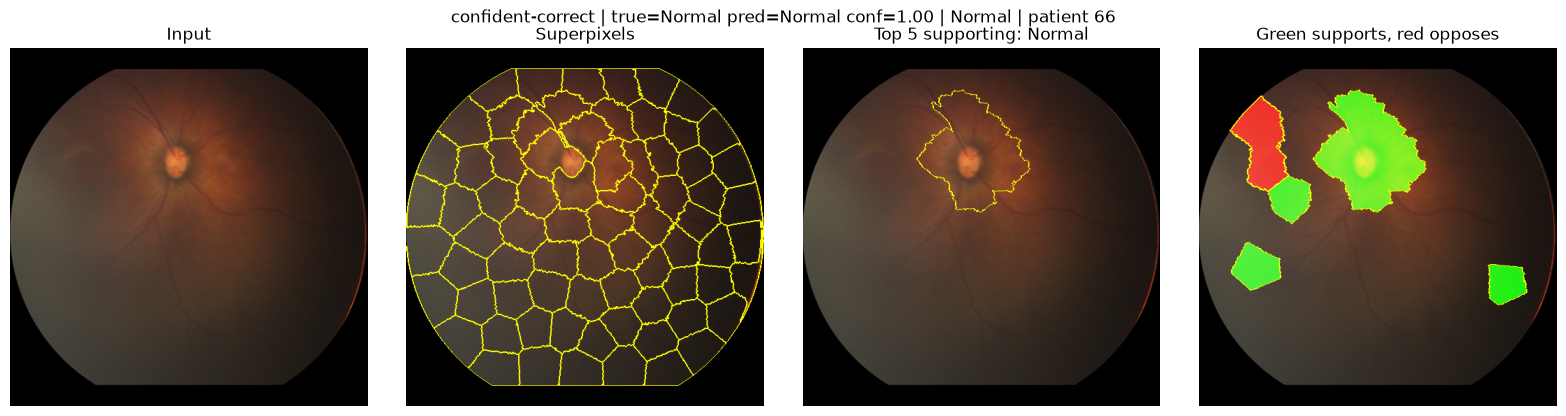

100%|██████████| 1000/1000 [00:10<00:00, 94.45it/s]


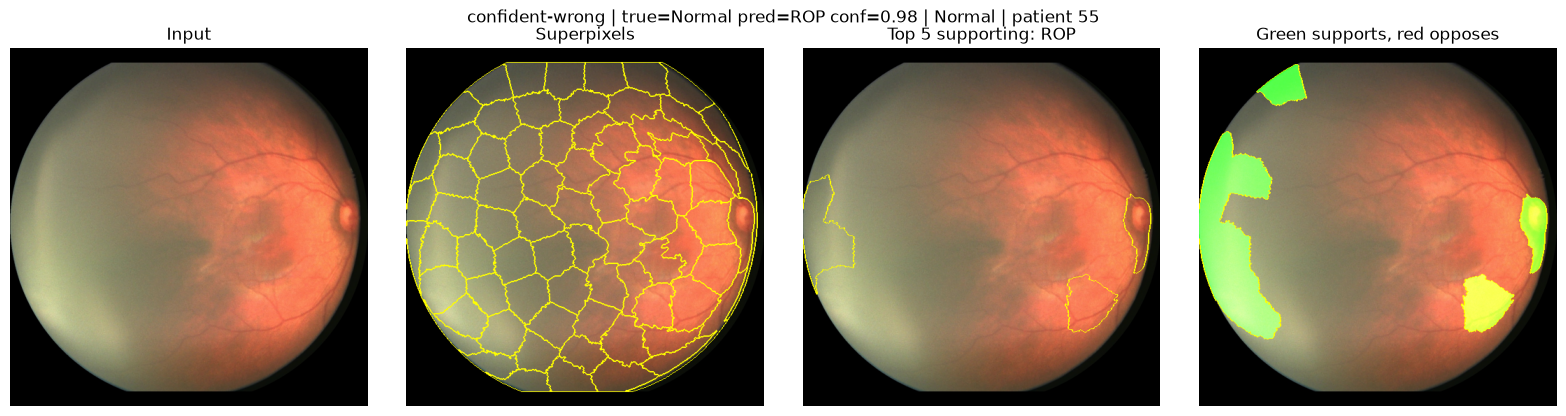

100%|██████████| 1000/1000 [00:10<00:00, 93.68it/s]


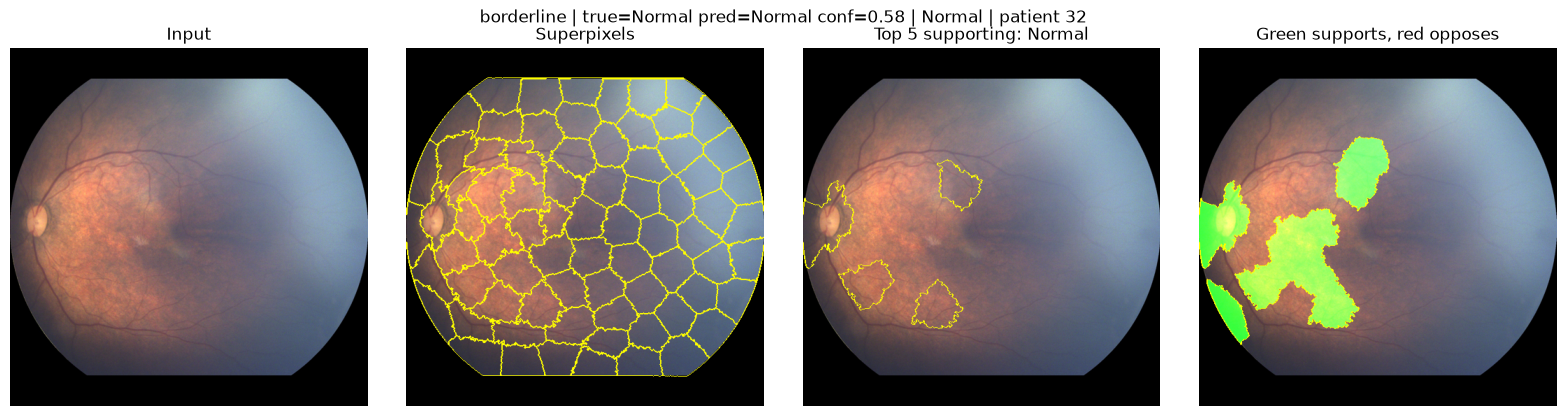

100%|██████████| 1000/1000 [00:10<00:00, 94.17it/s]


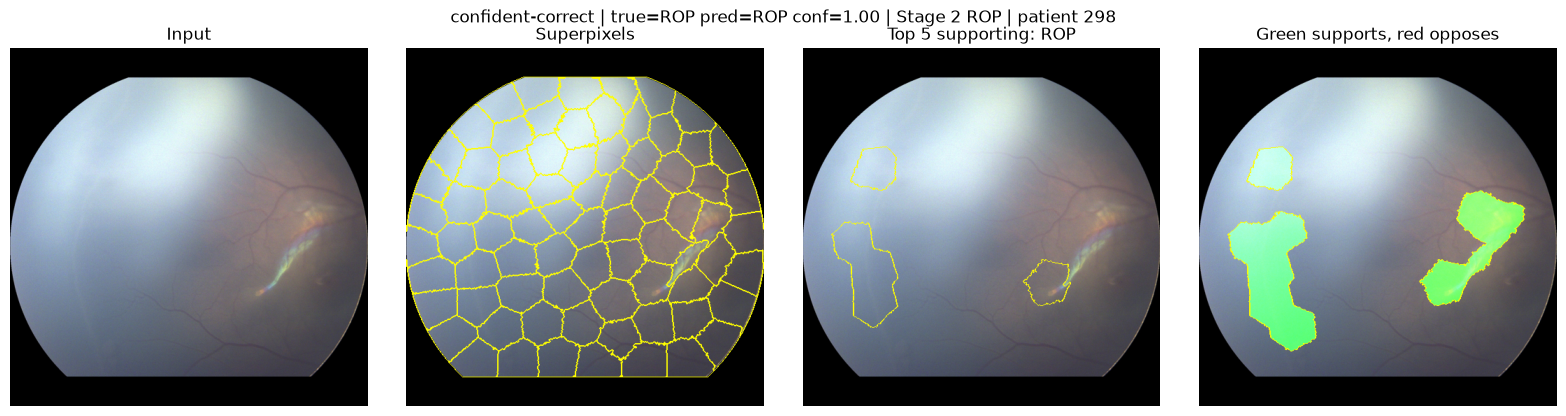

100%|██████████| 1000/1000 [00:10<00:00, 93.17it/s]


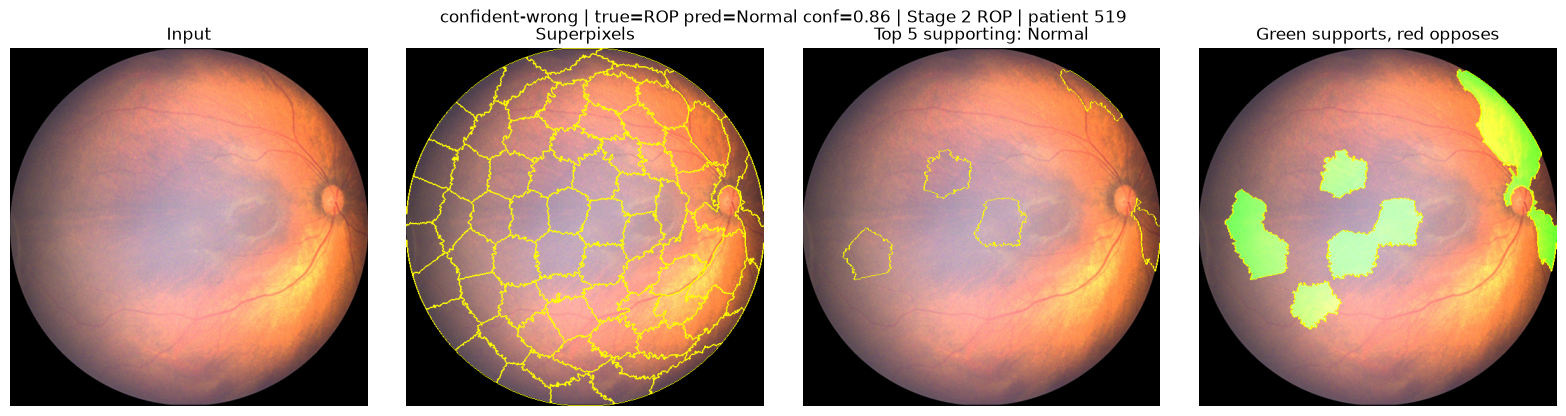

100%|██████████| 1000/1000 [00:10<00:00, 91.92it/s]


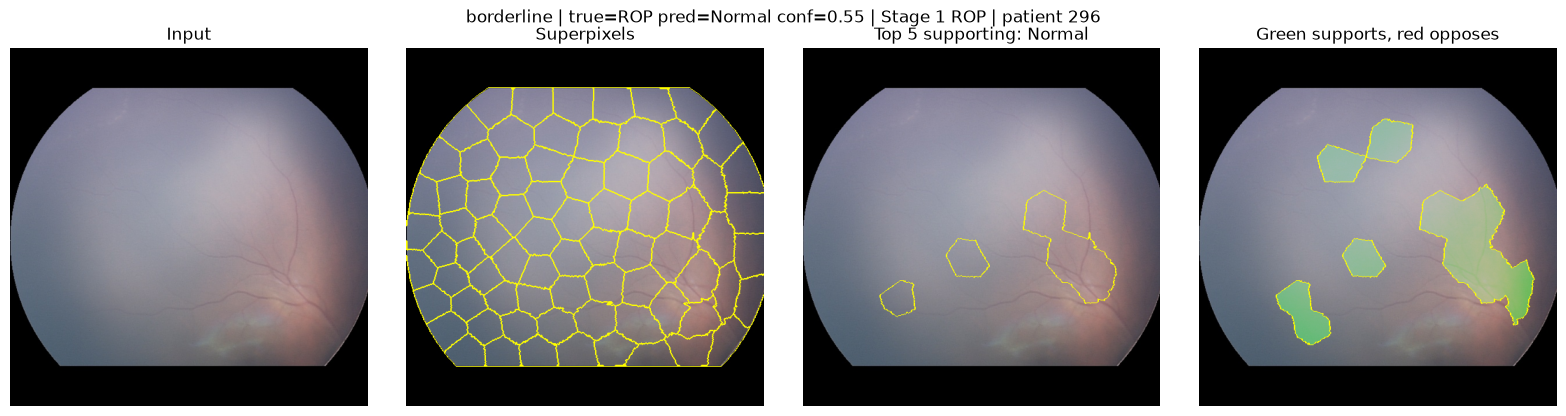

In [21]:
cases = pick_cases(occ_df, oof_occ, n_each=1)
print(cases)
explain_cases(cases, OCC_CLASSES, tag="occ")
# 1000 perturbed images per explanation, so this is slow on CPU. Lower num_samples or n_each to speed it up

# Quantifying the explanations

In [22]:
def border_checks(df, tag, n_classes, n_per_class=40, seed=0):
    """Does the model use the black border or its shape?
    (a) fill the border with the retina's mean color and see how much the prediction moves
    (b) blank the retina (mean color) and keep only the border, then see if the class can still be guessed"""
    rows = df.groupby("y", group_keys=False).sample(n_per_class, random_state=seed).index
    shifts, flips, border_only_pred, true = [], [], [], []
    for r in rows:
        img = X_all[r]
        inside = fundus_mask(img)
        mean_rgb = img[inside].mean(axis=0).astype(np.uint8)
        filled = img.copy();  filled[~inside] = mean_rgb          # (a) no border
        blank = img.copy();   blank[inside] = mean_rgb            # (b) no retina detail
        predict = make_predict_fn(get_fold_model(tag, int(imgs.loc[r, "fold"]), n_classes))
        p0, p1, p2 = predict(np.stack([img, filled, blank]))
        shifts.append(np.abs(p0 - p1).max());  flips.append(p0.argmax() != p1.argmax())
        border_only_pred.append(p2.argmax());  true.append(int(df.loc[r, "y"]))
    from sklearn.metrics import balanced_accuracy_score
    print(f"(a) border filled in: mean change in class probability {np.mean(shifts):.3f}, predictions flipped {np.mean(flips):.1%}")
    print(f"(b) border only: balanced accuracy {balanced_accuracy_score(true, border_only_pred):.3f} (0.5 = no information)")

def stability(model, img, label, k=5, seeds=(0, 1, 2), **kw):
    """Overlap (Jaccard) of the top k superpixels between LIME reruns with different seeds. 1.0 = identical."""
    tops = []
    for s in seeds:
        w = dict(explain(model, img, seed=s, **kw).local_exp[label])
        tops.append(set(sorted(w, key=lambda t: -w[t])[:k]))
    pairs = [(a, b) for i, a in enumerate(tops) for b in tops[i + 1:]]
    return float(np.mean([len(a & b) / len(a | b) for a, b in pairs]))
# the neighborhood / kernel choice is an unsolved problem in LIME, so low stability means the explanation
# should not be trusted yet (try more samples or fewer superpixels)

In [23]:
# the heading for this cell group is still "Quantifying the explanations"; these two tests need no LIME
border_checks(occ_df, tag="occ", n_classes=2)

(a) border filled in: mean change in class probability 0.047, predictions flipped 5.0%
(b) border only: balanced accuracy 0.513 (0.5 = no information)


In [24]:
# stability on a handful of images (3 LIME runs each)
rows = occ_df.groupby("ROP", group_keys=False).sample(3, random_state=0).index   # 3 Normal and 3 ROP images
for r in rows:
    model = get_fold_model("occ", int(imgs.loc[r, "fold"]), 2)
    lab = int(oof_occ[r].argmax())
    print(OCC_CLASSES[imgs.loc[r, "ROP"]], "stability:", round(stability(model, X_all[r], lab), 3))

100%|██████████| 1000/1000 [00:10<00:00, 93.16it/s]


Normal stability: 0.508


100%|██████████| 1000/1000 [00:10<00:00, 93.98it/s]


Normal stability: 0.157


100%|██████████| 1000/1000 [00:10<00:00, 93.74it/s]


Normal stability: 0.083


... (2 outputs left out)

100%|██████████| 1000/1000 [00:10<00:00, 93.08it/s]


ROP stability: 0.508


100%|██████████| 1000/1000 [00:10<00:00, 93.20it/s]

ROP stability: 0.429


# Ordinal metric for the severity task

In [25]:
from sklearn.metrics import cohen_kappa_score

def qwk(df, oof):
    # Mild < Moderate < Severe is ordered, so Severe predicted as Mild costs more than Severe predicted as Moderate
    y, pred = df["y"].to_numpy(), oof[df.index.to_numpy()].argmax(1)
    return round(cohen_kappa_score(y, pred, weights="quadratic"), 3)

# once the severity run is done:
# oof_sev = cross_validate(sev_df, n_classes=3, epochs=15, tag="sev", monitor="f1")
# report(sev_df, oof_sev, SEV_CLASSES); print("quadratic weighted kappa:", qwk(sev_df, oof_sev))